In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJDB12092/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,AGE,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,⋯,Organism,Platform,project_name,ReleaseDate,create_date,version,Sample.Name,Sample_name,sex,SRA.Study
,<chr>,<dbl>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,DRR314148,1.3,AMPLICON,600,21336115,PRJDB12092,SAMD00395979,MIMARKS.survey.human-oral,14046692,LION,⋯,human saliva metagenome,ILLUMINA,Analysis of salivary microbiome in Down syndrome,2022-10-12T00:00:00Z,2022-10-12T12:14:00Z,1,SAMD00395979,GM004,male,DRP009076
2,DRR314149,2.5,AMPLICON,600,16877725,PRJDB12092,SAMD00395980,MIMARKS.survey.human-oral,10937091,LION,⋯,human saliva metagenome,ILLUMINA,Analysis of salivary microbiome in Down syndrome,2022-10-12T00:00:00Z,2022-10-12T12:15:00Z,1,SAMD00395980,GM007,male,DRP009076
3,DRR314150,4.1,AMPLICON,600,25713139,PRJDB12092,SAMD00395981,MIMARKS.survey.human-oral,16867398,LION,⋯,human saliva metagenome,ILLUMINA,Analysis of salivary microbiome in Down syndrome,2022-10-12T00:00:00Z,2022-10-12T12:16:00Z,1,SAMD00395981,GM009,male,DRP009076
4,DRR314151,1.3,AMPLICON,600,24536201,PRJDB12092,SAMD00395982,MIMARKS.survey.human-oral,16098328,LION,⋯,human saliva metagenome,ILLUMINA,Analysis of salivary microbiome in Down syndrome,2022-10-12T00:00:00Z,2022-10-12T12:14:00Z,1,SAMD00395982,GM013,male,DRP009076
5,DRR314152,4.3,AMPLICON,600,28909681,PRJDB12092,SAMD00395983,MIMARKS.survey.human-oral,18914831,LION,⋯,human saliva metagenome,ILLUMINA,Analysis of salivary microbiome in Down syndrome,2022-10-12T00:00:00Z,2022-10-12T12:15:00Z,1,SAMD00395983,GM015,male,DRP009076
6,DRR314153,1.7,AMPLICON,600,27642160,PRJDB12092,SAMD00395984,MIMARKS.survey.human-oral,18159581,LION,⋯,human saliva metagenome,ILLUMINA,Analysis of salivary microbiome in Down syndrome,2022-10-12T00:00:00Z,2022-10-12T12:15:00Z,1,SAMD00395984,GM020,female,DRP009076


[1] "Run"                            "AGE"                           
 [3] "Assay.Type"                     "AvgSpotLen"                    
 [5] "Bases"                          "BioProject"                    
 [7] "BioSample"                      "BioSampleModel"                
 [9] "Bytes"                          "Center.Name"                   
[11] "Collection_Date"                "Consent"                       
[13] "DATASTORE.filetype"             "DATASTORE.provider"            
[15] "DATASTORE.region"               "env_broad_scale"               
[17] "env_local_scale"                "env_medium"                    
[19] "Experiment"                     "geo_loc_name_country"          
[21] "geo_loc_name_country_continent" "geo_loc_name"                  
[23] "host_disease_stat"              "HOST"                          
[25] "host_subject_id"                "Instrument"                    
[27] "lat_lon"                        "Library.Name"                  
[29] "LibraryLayout"                  "LibrarySelection"              
[31] "LibrarySource"                  "Organism"                      
[33] "Platform"                       "project_name"                  
[35] "ReleaseDate"                    "create_date"                   
[37] "version"                        "Sample.Name"                   
[39] "Sample_name"                    "sex"                           
[41] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample_name',
    Age = initial_meta$AGE,
    BMI = NA,
    Sex = initial_meta$sex,
    Region = 'V1-V2',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = "Salivary microbiome in children with Down syndrome: a case-control study",
    Disease_study = "YES",
    Status = initial_meta$host_disease_stat,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 54
[1] 54


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<dbl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<chr>,<chr>
1,PRJDB12092,DRR314148,GM004,1.3,NA,male,V1-V2,ILLUMINA,Japan,saliva,2022-10-12T00:00:00Z,NA,Salivary microbiome in children with Down syndrome: a case-control study,YES,Down syndrome,NO
2,PRJDB12092,DRR314149,GM007,2.5,NA,male,V1-V2,ILLUMINA,Japan,saliva,2022-10-12T00:00:00Z,NA,Salivary microbiome in children with Down syndrome: a case-control study,YES,Down syndrome,NO
3,PRJDB12092,DRR314150,GM009,4.1,NA,male,V1-V2,ILLUMINA,Japan,saliva,2022-10-12T00:00:00Z,NA,Salivary microbiome in children with Down syndrome: a case-control study,YES,Down syndrome,NO
4,PRJDB12092,DRR314151,GM013,1.3,NA,male,V1-V2,ILLUMINA,Japan,saliva,2022-10-12T00:00:00Z,NA,Salivary microbiome in children with Down syndrome: a case-control study,YES,Down syndrome,NO
5,PRJDB12092,DRR314152,GM015,4.3,NA,male,V1-V2,ILLUMINA,Japan,saliva,2022-10-12T00:00:00Z,NA,Salivary microbiome in children with Down syndrome: a case-control study,YES,Down syndrome,NO
6,PRJDB12092,DRR314153,GM020,1.7,NA,female,V1-V2,ILLUMINA,Japan,saliva,2022-10-12T00:00:00Z,NA,Salivary microbiome in children with Down syndrome: a case-control study,YES,Down syndrome,NO


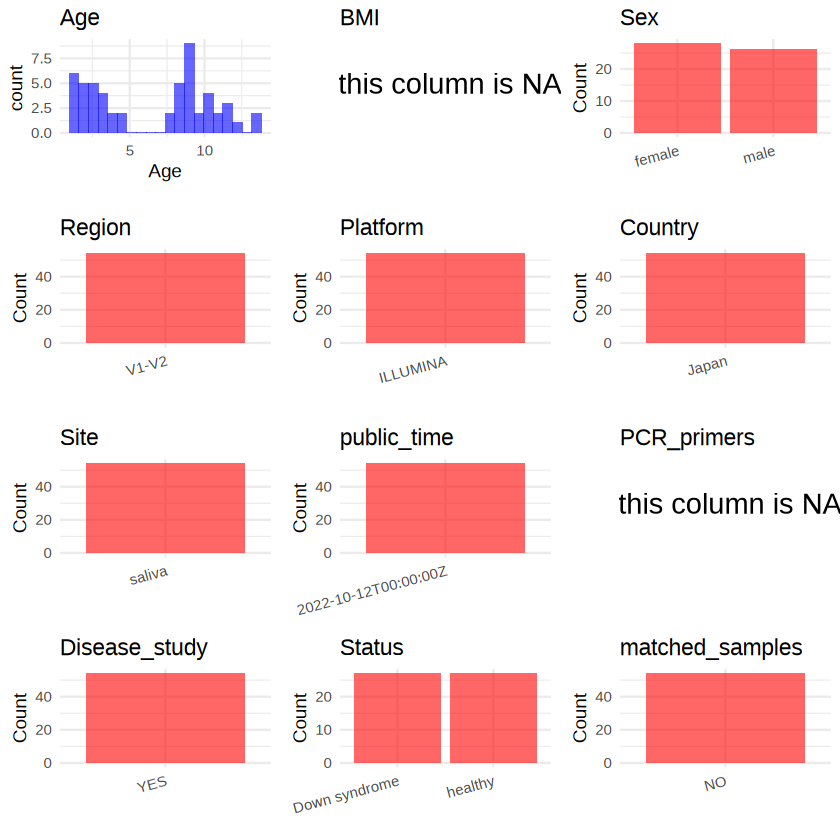

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJDB12092/metadata.csv", quote = T)